In [1]:
import numpy as np
import time
from datetime import timedelta
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, GlobalMaxPooling1D, Flatten, Dense, Dropout, Input, BatchNormalization, GlobalAveragePooling1D
from keras.optimizers import Adam

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, average_precision_score
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from tensorflow.keras.regularizers import l2

from tensorflow.keras.layers import LSTM

import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Data shtuff

In [42]:
path = r"/content/drive/MyDrive/datasets/duplicates/combined_3sec.csv"
df = pd.read_csv(path)

In [43]:
display(df)

,2_0,3_0,4_0,5_0,6_0,7_0,8_0,9_0,10_0,11_0,...,35_59,36_59,37_59,38_59,39_59,40_59,41_59,42_59,43_59,target
0,1.0,1.0,0.0,1.0,27.0,-1.398295,4.552336,8.461134,9.709263,-1.573943,...,-0.303537,0.918777,0.174533,1.015117,34.030823,-27.510532,-10.321811,44.960716,14.0,0
1,1.0,7.0,0.0,1.0,27.0,-1.573461,4.591024,8.289808,9.605946,-1.757124,...,-0.299257,0.916774,0.174533,1.015117,33.997740,-29.681087,-8.131886,45.857834,14.0,0
2,1.0,13.0,0.0,1.0,27.0,-1.605537,4.884261,8.589285,10.010473,-1.387172,...,-0.303231,0.915937,0.174533,1.015117,35.242370,-30.081463,-5.180584,46.623570,14.0,0
3,1.0,19.0,0.0,1.0,27.0,-0.849014,4.889525,8.464052,9.811649,-0.871612,...,-0.310448,0.909323,0.174533,1.015117,35.767944,-31.508389,-6.842484,48.155415,14.0,0
4,1.0,23.0,0.0,1.0,27.0,-1.315205,5.121365,8.149573,9.714612,-1.208508,...,-0.296095,0.901608,0.174533,1.015117,33.017273,-35.450974,-10.435835,49.556213,14.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25666,1.0,47.0,3.0,7.0,67.0,-0.203513,8.085466,5.916253,10.020890,-0.071470,...,0.612532,0.635370,0.000000,0.999999,271.793300,-56.084957,0.970513,277.521300,0.0,1
25667,1.0,50.0,3.0,7.0,67.0,0.292102,8.020821,5.719923,9.855780,0.137863,...,0.585291,0.650928,0.000000,0.999999,275.170620,-57.712128,2.815787,281.171630,0.0,1
25668,1.0,52.0,3.0,7.0,67.0,0.495615,8.336864,5.375147,9.931825,0.407753,...,0.630717,0.628608,0.000000,0.999999,269.825680,-54.132760,-0.057905,275.202200,0.0,1
25669,1.0,59.0,3.0,7.0,67.0,0.696734,7.874770,5.602603,9.689510,-0.008032,...,0.620318,0.639488,0.000000,0.999999,271.841200,-54.020080,-0.324217,277.156830,0.0,1


In [ ]:
df.info()

In [ ]:
df.describe()

In [ ]:
#shapes = pd.DataFrame({
#    "DataFrame": ["original", "1 sec", "3 secs", "5 secs", "7 secs"],
#    "Shape": [df0.shape, df1.shape, df3.shape, df5.shape, df7.shape],
#    "Total Elements": [df0.shape[0] * df0.shape[1], df1.shape[0] * df1.shape[1],
#                       df3.shape[0] * df3.shape[1], df5.shape[0] * df5.shape[1],
#                       df7.shape[0] * df7.shape[1]]
#})

#display(shapes)

,DataFrame,Shape,Total Elements
0,original,"(1540372, 43)",66235996
1,1 sec,"(77017, 841)",64771297
2,3 secs,"(25671, 2521)",64716591
3,5 secs,"(15402, 4201)",64703802
4,7 secs,"(11002, 5881)",64702762


In [44]:
target_distribution = df['target'].value_counts(normalize=True)
print(target_distribution)

target
1    0.542714
0    0.457286
Name: proportion, dtype: float64


In [45]:
def data_splitting(df):
    X = df.drop(columns = ["target"])
    y = df["target"]

    # Standardize the data
    scaler = StandardScaler()
    X = scaler.fit_transform(X)

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify = y)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=42, stratify = y_train)


    # Standardize the data
    #scaler = StandardScaler()
    #X_train = scaler.fit_transform(X_train)
    #X_test = scaler.transform(X_test)
    #X_val = scaler.transform(X_val)

    #print(X_train.shape, y_train.shape)
    #print(X_val.shape, y_val.shape)
    #print(X_test.shape, y_test.shape)

    shapes_df = pd.DataFrame({
        'Set': ['Training Set', 'Validation Set', 'Test Set'],
        'Features Shape': [X_train.shape, X_val.shape, X_test.shape],
        'Labels Shape': [y_train.shape, y_val.shape, y_test.shape]
                })

    display(shapes_df)

    return X_train, y_train, X_val, y_val, X_test, y_test




In [46]:
X_train, y_train, X_val, y_val, X_test, y_test = data_splitting(df)

,Set,Features Shape,Labels Shape
0,Training Set,"(18482, 2520)","(18482,)"
1,Validation Set,"(2054, 2520)","(2054,)"
2,Test Set,"(5135, 2520)","(5135,)"


In [47]:
# Compute class weights
class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = dict(enumerate(class_weights))
print(class_weights_dict)

{0: 1.0933506862281117, 1: 0.9213359920239282}


# Models

## FNN

In [48]:
def fnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):
    # Assuming X_train is already defined
    input_shape = X_train.shape[1]

    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)

    # Build the model
    fnn_model = Sequential()
    fnn_model.add(Input(shape=(input_shape,)))
    fnn_model.add(Dense(512, activation='relu'))
    fnn_model.add(Dropout(0.3))
    fnn_model.add(Dense(256, activation='relu'))
    fnn_model.add(Dropout(0.3))
    fnn_model.add(Dense(128, activation='relu', kernel_regularizer=l2(0.01)))
    fnn_model.add(Dropout(0.5))
    fnn_model.add(Dense(64, activation='relu', kernel_regularizer=l2(0.01)))
    fnn_model.add(Dropout(0.6))
    fnn_model.add(Dense(32, activation='relu'))
    fnn_model.add(Dropout(0.6))
    fnn_model.add(Dense(1, activation='sigmoid'))
    fnn_model.summary()

    # Compile the model
    fnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

    # Train the model
    start_time_fnn = time.time()
    fnn_history = fnn_model.fit(X_train, y_train
                        ,validation_data = (X_val, y_val)
                        ,epochs = 100
                        ,batch_size = 32
                        ,callbacks = [reduce_lr, early_stopping]
                        ,class_weight = class_weights_dict
                        )
    end_time_fnn = time.time()


    # Calculate the elapsed time
    training_time_fnn = end_time_fnn - start_time_fnn
    print(f"FNN Model training time: {training_time_fnn:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_fnn)
    milliseconds = int(training_time_fnn * 1000) % 1000
    print(f"FNN Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")


    # Predict on test data
    fnn_y_pred_prob = fnn_model.predict(X_test)
    fnn_y_pred = (fnn_y_pred_prob > 0.5).astype(int)


    # result calculation
    cm = confusion_matrix(y_test, fnn_y_pred)
    cr = classification_report(y_test, fnn_y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, fnn_y_pred).ravel()

    precision = precision_score(y_test, fnn_y_pred)
    recall = recall_score(y_test, fnn_y_pred)
    f1 = f1_score(y_test, fnn_y_pred)
    accuracy = accuracy_score(y_test, fnn_y_pred)
    specificity = tn / (tn + fp)

    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test, fnn_y_pred_prob)
    roc_auc = roc_auc_score(y_test, fnn_y_pred_prob)

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, fnn_y_pred_prob)
    avg_precision = average_precision_score(y_test, fnn_y_pred_prob)

    return [fnn_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [49]:
[fnn_history, fnn_cm, fnn_cr, fnn_accuracy, fnn_precision, fnn_recall,
    fnn_f1, fnn_specificity, fnn_roc_auc, fnn_avg_precision, fnn_fpr, fnn_tpr, fnn_thresholds,
    fnn_precision_vals, fnn_recall_vals, fnn_pr_thresholds] = fnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)


Model: "sequential_3"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_10 (Dense)            (None, 512)               1290752   
                                                                 
 dropout_16 (Dropout)        (None, 512)               0         
                                                                 
 dense_11 (Dense)            (None, 256)               131328    
                                                                 
 dropout_17 (Dropout)        (None, 256)               0         
                                                                 
 dense_12 (Dense)            (None, 128)               32896     
                                                                 
 dropout_18 (Dropout)        (None, 128)               0         
                                                                 
 dense_13 (Dense)            (None, 64)               

## CNN

In [50]:
def cnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):
    # Reshape data for Conv1D
    cnn_X_train = X_train.reshape((X_train.shape[0], X_train.shape[1], 1))
    cnn_X_test = X_test.reshape((X_test.shape[0], X_test.shape[1], 1))
    cnn_X_val = X_val.reshape((X_val.shape[0], X_val.shape[1], 1))


    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)


    # Build and train the CNN model
    cnn_model = Sequential([
        Conv1D(filters=64, kernel_size=7, activation='relu', input_shape=(cnn_X_train.shape[1], 1), kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        Dropout(0.3),

        Conv1D(filters=64, kernel_size=7, activation='relu', kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        #GlobalMaxPooling1D(),
        Dropout(0.6),

        #Conv1D(filters=128, kernel_size=7, activation='relu', kernel_regularizer=l2(0.01)),
        #BatchNormalization(),
        #MaxPooling1D(pool_size=5),
        Dropout(0.6),
        #GlobalMaxPooling1D(),

        Flatten(),
        Dense(128, activation='relu'),# kernel_regularizer=l2(0.01)),
        Dropout(0.6),
        #Dense(128, activation='relu', kernel_regularizer=l2(0.01)),
        #Dropout(0.5),
        #Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
        #Dropout(0.5),
        Dense(32, activation='relu'),# kernel_regularizer=l2(0.01)),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    cnn_model.summary()

    cnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

    start_time_cnn = time.time()
    cnn_history = cnn_model.fit(cnn_X_train, y_train
                                ,validation_data=(cnn_X_val, y_val)
                                ,epochs=100
                                ,batch_size=32
                                ,callbacks=[early_stopping, reduce_lr]
                                ,class_weight = class_weights_dict
                                )
    end_time_cnn = time.time()

    # Calculate the elapsed time
    training_time_cnn = end_time_cnn - start_time_cnn
    print(f"FNN Model training time: {training_time_cnn:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_cnn)
    milliseconds = int(training_time_cnn * 1000) % 1000
    print(f"FNN Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")

    # Evaluate CNN model
    cnn_y_pred_prob = cnn_model.predict(cnn_X_test)
    cnn_y_pred = (cnn_y_pred_prob > 0.5).astype(int)

    # result calculation
    cm = confusion_matrix(y_test, cnn_y_pred)
    cr = classification_report(y_test, cnn_y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, cnn_y_pred).ravel()

    precision = precision_score(y_test, cnn_y_pred)
    recall = recall_score(y_test, cnn_y_pred)
    f1 = f1_score(y_test, cnn_y_pred)
    accuracy = accuracy_score(y_test, cnn_y_pred)
    specificity = tn / (tn + fp)


    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test, cnn_y_pred_prob)
    roc_auc = roc_auc_score(y_test, cnn_y_pred_prob)

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, cnn_y_pred_prob)
    avg_precision = average_precision_score(y_test, cnn_y_pred_prob)

    return [cnn_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [51]:
#cnn model
[cnn_history, cnn_cm, cnn_cr, cnn_accuracy, cnn_precision, cnn_recall,
    cnn_f1, cnn_specificity, cnn_roc_auc, cnn_avg_precision, cnn_fpr, cnn_tpr, cnn_thresholds,
    cnn_precision_vals, cnn_recall_vals, cnn_pr_thresholds] = cnn_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)

Model: "sequential_4"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d_2 (Conv1D)           (None, 2514, 64)          512       
                                                                 
 dropout_21 (Dropout)        (None, 2514, 64)          0         
                                                                 
 conv1d_3 (Conv1D)           (None, 2508, 64)          28736     
                                                                 
 dropout_22 (Dropout)        (None, 2508, 64)          0         
                                                                 
 dropout_23 (Dropout)        (None, 2508, 64)          0         
                                                                 
 flatten_1 (Flatten)         (None, 160512)            0         
                                                                 
 dense_16 (Dense)            (None, 128)              

## LSTM

In [52]:
def lstm_model_definition(X_train, y_train, X_val, y_val, X_test, y_test):

    X_train_lstm = X_train.reshape(X_train.shape[0], 1, X_train.shape[1])
    X_test_lstm = X_test.reshape(X_test.shape[0], 1, X_test.shape[1])
    X_val_lstm = X_val.reshape(X_val.shape[0], 1, X_val.shape[1])

    # Define early stopping with patience
    early_stopping = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=0.0001)

    # LSTM
    model = Sequential()
    model.add(LSTM(units=256, return_sequences=True, input_shape=(X_train_lstm.shape[1], X_train_lstm.shape[2])))
    model.add(Dropout(0.3))
    model.add(BatchNormalization())

    model.add(LSTM(units=128, return_sequences=True))
    model.add(Dropout(0.3))
    model.add(BatchNormalization())

    model.add(LSTM(units=64, return_sequences=True))
    model.add(Dropout(0.5))
    model.add(BatchNormalization())

    model.add(LSTM(units=32, return_sequences=True))
    model.add(Dropout(0.5))
    #model.add(BatchNormalization())

    model.add(LSTM(units=16, return_sequences=True))
    model.add(Dropout(0.6))
    model.add(BatchNormalization())

    model.add(LSTM(units=8))
    model.add(Dropout(0.6))
    model.add(BatchNormalization())

    model.add(Dense(units=1, activation='sigmoid'))

    model.summary()

    # Compile the model
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])  # Adjust loss and metrics as per your task

    # Train the model
    start_time_lstm = time.time()
    lstm_history = model.fit(X_train_lstm, y_train
                            ,epochs=100
                            ,batch_size=32
                            ,validation_data=(X_val_lstm, y_val)
                            ,callbacks = [reduce_lr, early_stopping]
                            ,class_weight = class_weights_dict
                             )
    end_time_lstm = time.time()

    # Calculate the elapsed time
    training_time_lstm = end_time_lstm - start_time_lstm
    print(f"FNN Model training time: {training_time_lstm:.2f} seconds")
    # Convert time to minutes, seconds, and milliseconds
    td = timedelta(seconds=training_time_lstm)
    milliseconds = int(training_time_lstm * 1000) % 1000
    print(f"FNN Model training time: {td.seconds // 60} minutes, {td.seconds % 60} seconds, and {milliseconds} milliseconds")


    lstm_y_pred_prob = model.predict(X_test_lstm)
    lstm_y_pred = (lstm_y_pred_prob > 0.5).astype(int)


    # result calculation
    cm = confusion_matrix(y_test, lstm_y_pred)
    cr = classification_report(y_test, lstm_y_pred)

    tn, fp, fn, tp = confusion_matrix(y_test, lstm_y_pred).ravel()

    precision = precision_score(y_test, lstm_y_pred)
    recall = recall_score(y_test, lstm_y_pred)
    f1 = f1_score(y_test, lstm_y_pred)
    accuracy = accuracy_score(y_test, lstm_y_pred)
    specificity = tn / (tn + fp)

    # ROC AUC Curve
    fpr, tpr, thresholds = roc_curve(y_test, lstm_y_pred_prob)
    roc_auc = roc_auc_score(y_test, lstm_y_pred_prob)

    # Precision-Recall Curve
    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, lstm_y_pred_prob)
    avg_precision = average_precision_score(y_test, lstm_y_pred_prob)

    return [lstm_history, cm, cr, accuracy, precision, recall,
            f1, specificity, roc_auc, avg_precision, fpr, tpr, thresholds,
            precision_vals, recall_vals, pr_thresholds]


In [53]:
#lstm model
[lstm_history, lstm_cm, lstm_cr, lstm_accuracy, lstm_precision, lstm_recall,
    lstm_f1, lstm_specificity, lstm_roc_auc, lstm_avg_precision, lstm_fpr, lstm_tpr, lstm_thresholds,
    lstm_precision_vals, lstm_recall_vals, lstm_pr_thresholds] = lstm_model_definition(X_train, y_train, X_val, y_val, X_test, y_test)

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_6 (LSTM)               (None, 1, 256)            2843648   
                                                                 
 dropout_26 (Dropout)        (None, 1, 256)            0         
                                                                 
 batch_normalization_5 (Bat  (None, 1, 256)            1024      
 chNormalization)                                                
                                                                 
 lstm_7 (LSTM)               (None, 1, 128)            197120    
                                                                 
 dropout_27 (Dropout)        (None, 1, 128)            0         
                                                                 
 batch_normalization_6 (Bat  (None, 1, 128)            512       
 chNormalization)                                     

# Results

## FNN

In [66]:
print("FNN model:")
print("Accuracy: ", fnn_accuracy)
print("Precision: ", fnn_precision)
print("Recall: ", fnn_recall)
print("F1 score: ", fnn_f1)
print("Specificity: ", fnn_specificity)
print("AUC-ROC:", fnn_roc_auc)

FNN model:
Accuracy:  0.8965920155793573
Precision:  0.9548387096774194
Recall:  0.849659131682813
F1 score:  0.8991835959749382
Specificity:  0.9522998296422487
AUC-ROC: 0.9658216323169938


In [55]:
print("fnn_avg_precision: ", fnn_avg_precision)
print("fnn_fpr: ", fnn_fpr)
print("fnn_tpr: ", fnn_tpr)
print("fnn_thresholds: ", fnn_thresholds)
print("fnn_precision_vals: ", fnn_precision_vals)
print("fnn_recall_vals: ", fnn_recall_vals)
print("fnn_pr_thresholds: ", fnn_pr_thresholds)

fnn_avg_precision:  0.9707976523778834
fnn_fpr:  [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 4.25894378e-04 4.25894378e-04
 4.25894378e-04 8.51788756e-04 8.51788756e-04 8.51788756e-04
 8.51788756e-04 8.51788756e-04 8.51788756e-04 8.51788756e-04
 8.51788756e-04 8.51788756e-04 8.51788756e-04 8.51788756e-04
 8.51788756e-04 8.51788756e-04 8.51788756e-04 8.51788756e-04
 8.51788756e-04 8.51788756e-04 8.51788756e-04 8.51788756e-04
 8.51788756e-04 1.27768313e-03 1.27768313e-03 1.27768313e-03
 1.27768313e-03 1.27768313e-03 1.27768313e-03 1.27768313e-03
 1.27768313e-03 1.27768313e-03 1.27768313e-03 1.27768313e-03
 1.27768313e-03 1.27768313e-03 1.27768313e-03 1.27768313e-03
 1.27768313e-03 1.27768313e-03 1.27768313e-03 1.27768313e-03
 1.27768313e-03 1.27768313e-03 1.27768313e-03 1.27768313e-03
 1.27768313e-03 1.27768313e-03 1.27768313e-03 1.27768313e-03
 1.27768313e-03 1.27768313e-03 1.27768313e-03 1.27768313e-03
 1.27768313e-03 1.27768313e-03 1.277

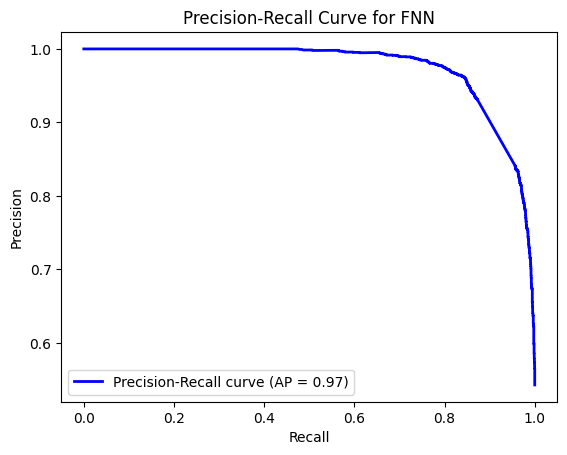

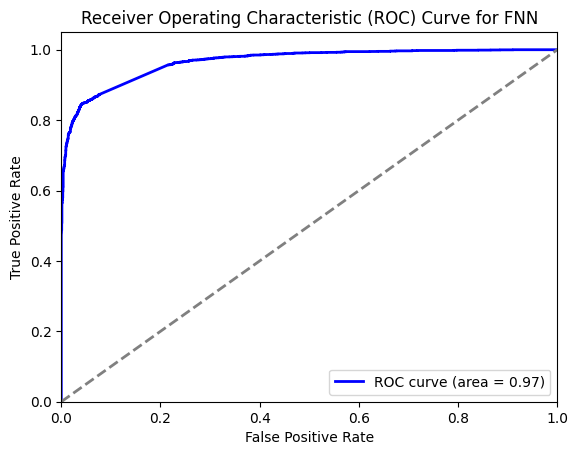

In [56]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(fnn_recall_vals, fnn_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {fnn_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for FNN')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(fnn_fpr, fnn_tpr, color='blue', lw=2, label=f'ROC curve (area = {fnn_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for FNN')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[2236  112]
 [ 419 2368]]


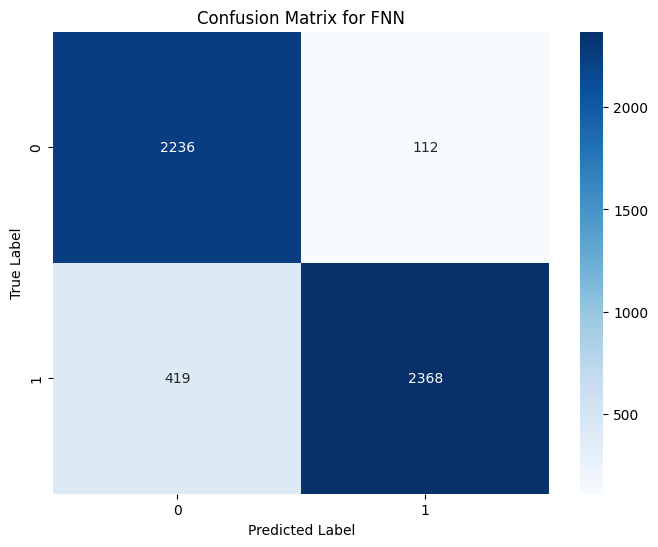

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      2348
           1       0.95      0.85      0.90      2787

    accuracy                           0.90      5135
   macro avg       0.90      0.90      0.90      5135
weighted avg       0.90      0.90      0.90      5135



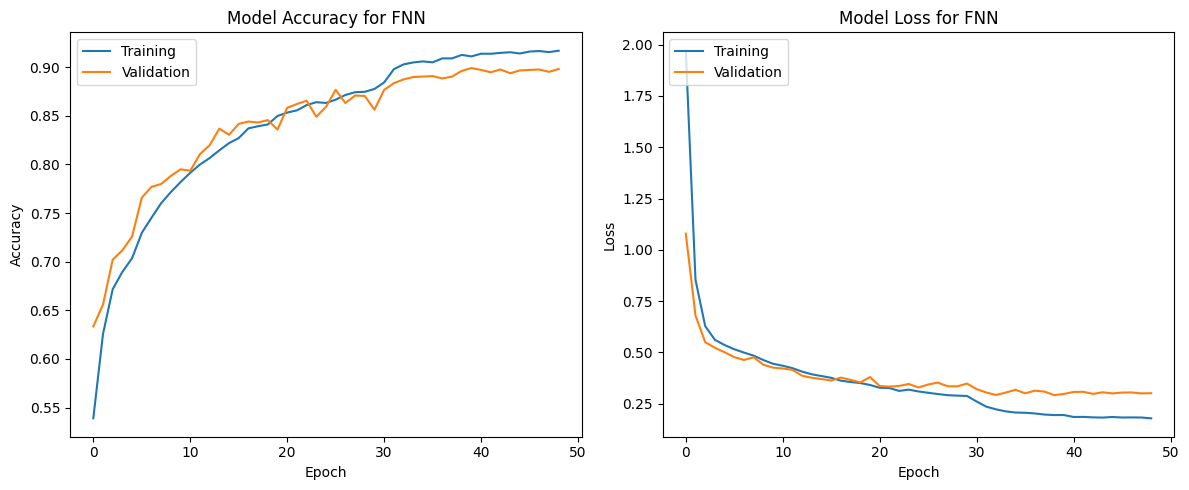

In [57]:
print("Confusion Matrix:")
print(fnn_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(fnn_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for FNN')
plt.show()

print("Classification report:")
print(fnn_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for FNN')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for FNN')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(fnn_history)

## CNN

In [67]:
print("CNN model:")
print("Accuracy: ", cnn_accuracy)
print("Precision: ", cnn_precision)
print("Recall: ", cnn_recall)
print("F1 score: ", cnn_f1)
print("Specificity: ", cnn_specificity)
print("AUC-ROC:", cnn_roc_auc)

CNN model:
Accuracy:  0.9300876338851023
Precision:  0.9420975965040058
Recall:  0.9282382490132759
F1 score:  0.9351165732875474
Specificity:  0.932282793867121
AUC-ROC: 0.9841896454028163


In [59]:
print("cnn_avg_precision: ", cnn_avg_precision)
print("cnn_fpr: ", cnn_fpr)
print("cnn_tpr: ", cnn_tpr)
print("cnn_thresholds: ", cnn_thresholds)
print("cnn_precision_vals: ", cnn_precision_vals)
print("cnn_recall_vals: ", cnn_recall_vals)
print("cnn_pr_thresholds: ", cnn_pr_thresholds)

cnn_avg_precision:  0.9876399830937628
cnn_fpr:  [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 4.25894378e-04 4.25894378e-04
 8.51788756e-04 8.51788756e-04 1.27768313e-03 1.27768313e-03
 1.70357751e-03 1.70357751e-03 2.12947189e-03 2.12947189e-03
 2.55536627e-03 2.55536627e-03 2.98126065e-03 2.98126065e-03
 3.40715503e-03 3.40715503e-03 3.83304940e-03 3.83304940e-03
 4.25894378e-03 4.25894378e-03 4.684

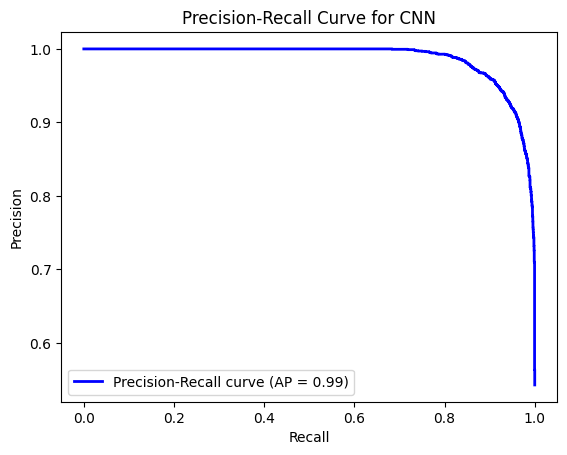

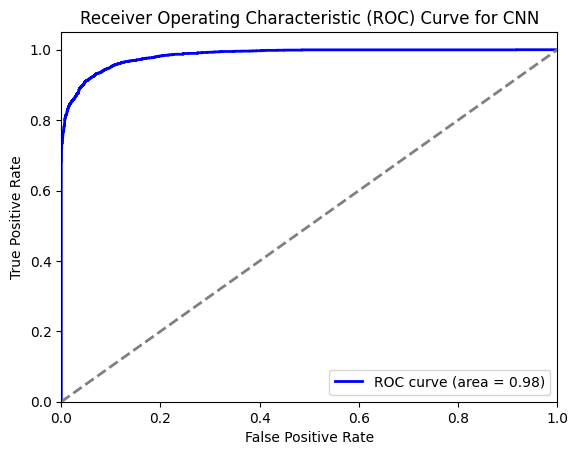

In [60]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(cnn_recall_vals, cnn_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {cnn_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for CNN')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(cnn_fpr, cnn_tpr, color='blue', lw=2, label=f'ROC curve (area = {cnn_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for CNN')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[2189  159]
 [ 200 2587]]


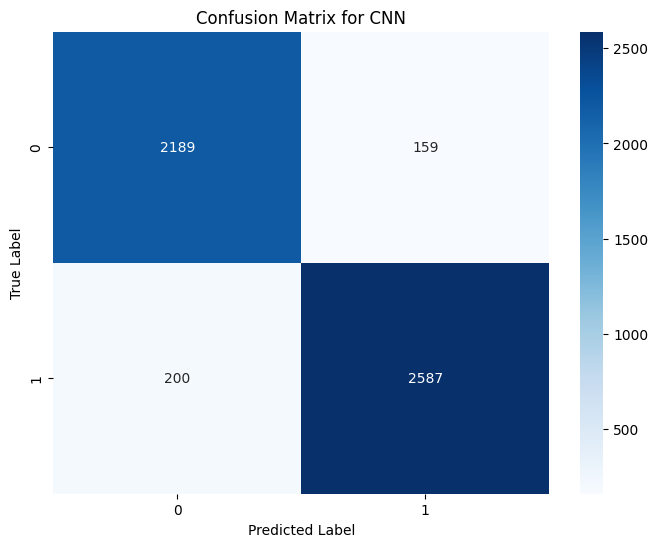

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.92      2348
           1       0.94      0.93      0.94      2787

    accuracy                           0.93      5135
   macro avg       0.93      0.93      0.93      5135
weighted avg       0.93      0.93      0.93      5135



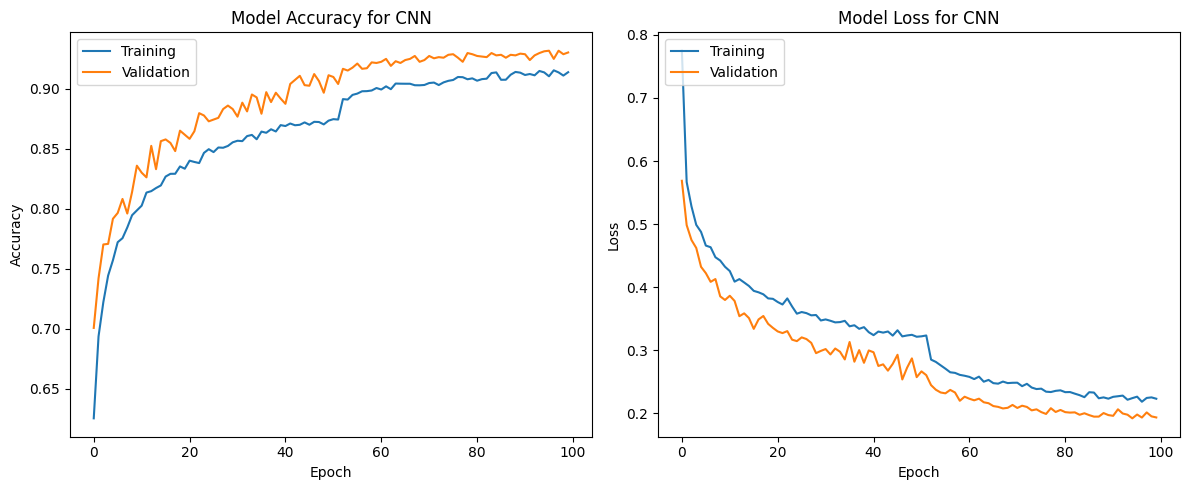

In [61]:
print("Confusion Matrix:")
print(cnn_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(cnn_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for CNN')
plt.show()

print("Classification report:")
print(cnn_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for CNN')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for CNN')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(cnn_history)

## LSTM

In [68]:
print("LSTM model:")
print("Accuracy: ", lstm_accuracy)
print("Precision: ", lstm_precision)
print("Recall: ", lstm_recall)
print("F1 score: ", lstm_f1)
print("Specificity: ", lstm_specificity)
print("AUC-ROC:", lstm_roc_auc)

LSTM model:
Accuracy:  0.9139240506329114
Precision:  0.9396325459317585
Recall:  0.8991747398636527
F1 score:  0.918958562522919
Specificity:  0.9314310051107325
AUC-ROC: 0.9773930618489716


In [63]:
print("lstm_avg_precision: ", lstm_avg_precision)
print("lstm_fpr: ", lstm_fpr)
print("lstm_tpr: ", lstm_tpr)
print("lstm_thresholds: ", lstm_thresholds)
print("lstm_precision_vals: ", lstm_precision_vals)
print("lstm_recall_vals: ", lstm_recall_vals)
print("lstm_pr_thresholds: ", lstm_pr_thresholds)

lstm_avg_precision:  0.9819922826590248
lstm_fpr:  [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.0

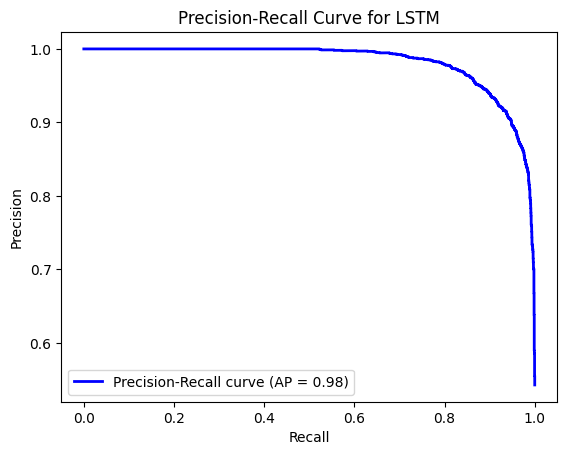

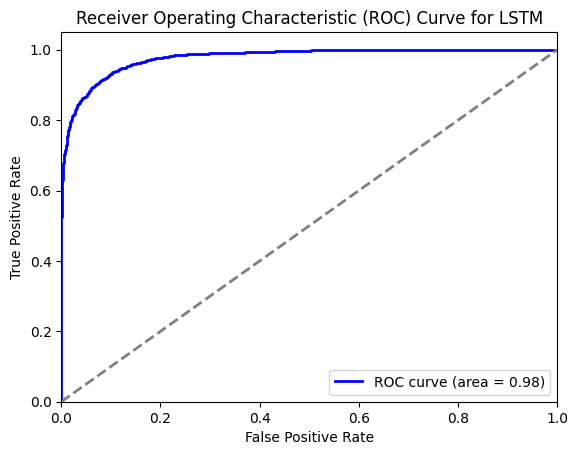

In [64]:
# Plot Precision-Recall Curve
plt.figure()
plt.plot(lstm_recall_vals, lstm_precision_vals, color='blue', lw=2, label=f'Precision-Recall curve (AP = {lstm_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for LSTM')
plt.legend(loc="lower left")
plt.show()

# Plot ROC AUC Curve
plt.figure()
plt.plot(lstm_fpr, lstm_tpr, color='blue', lw=2, label=f'ROC curve (area = {lstm_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for LSTM')
plt.legend(loc="lower right")
plt.show()

Confusion Matrix:
[[2187  161]
 [ 281 2506]]


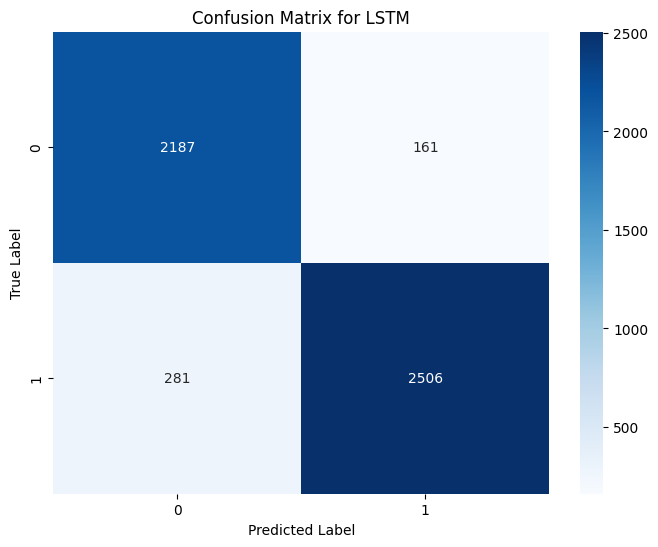

Classification report:
              precision    recall  f1-score   support

           0       0.89      0.93      0.91      2348
           1       0.94      0.90      0.92      2787

    accuracy                           0.91      5135
   macro avg       0.91      0.92      0.91      5135
weighted avg       0.92      0.91      0.91      5135



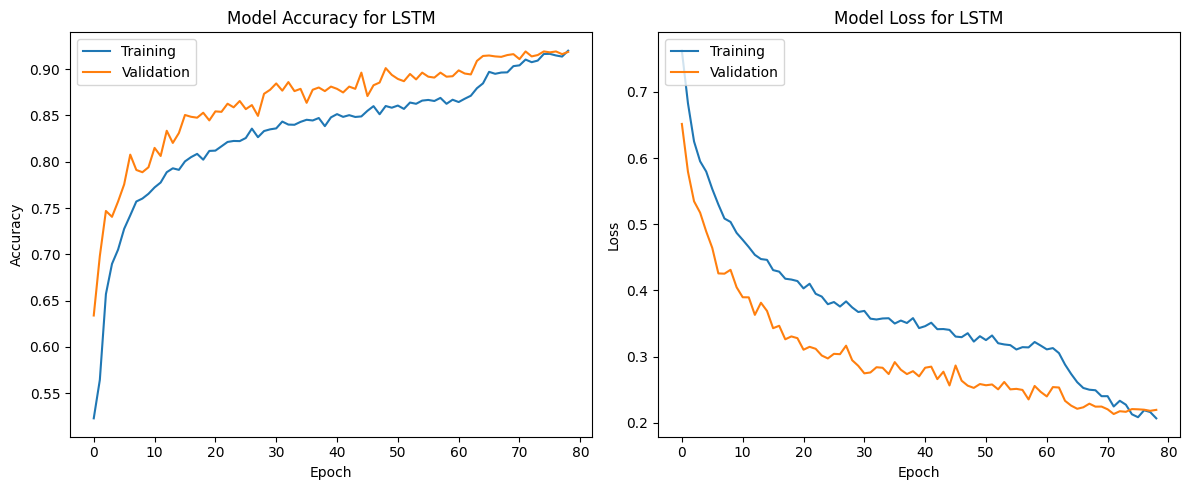

In [65]:
print("Confusion Matrix:")
print(lstm_cm)
plt.figure(figsize=(8, 6))
sns.heatmap(lstm_cm, annot=True, cmap='Blues', fmt='g')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for LSTM')
plt.show()

print("Classification report:")
print(lstm_cr)

# Plotting the training and validation accuracy and loss
def plot_training_history(history):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model Accuracy for LSTM')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='upper left')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model Loss for LSTM')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

# Plot the training history
plot_training_history(lstm_history)

## Combined

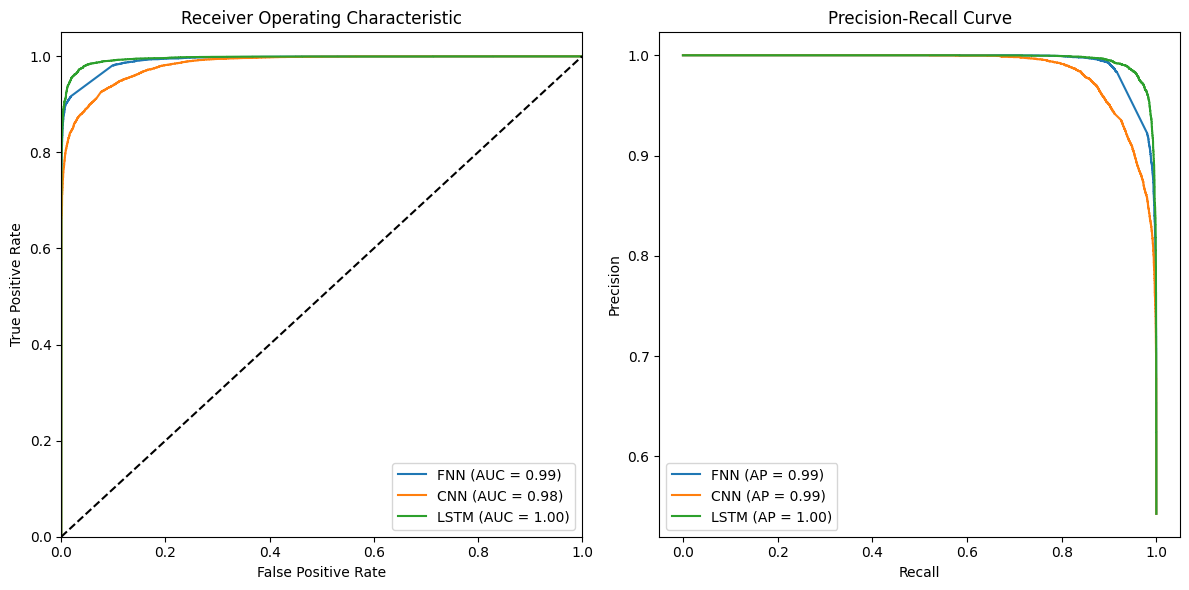

In [40]:
# Plot ROC curves
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(fnn_fpr, fnn_tpr, label=f'FNN (AUC = {fnn_roc_auc:.2f})')
plt.plot(cnn_fpr, cnn_tpr, label=f'CNN (AUC = {cnn_roc_auc:.2f})')
plt.plot(lstm_fpr, lstm_tpr, label=f'LSTM (AUC = {lstm_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")

# Plot Precision-Recall curves
plt.subplot(1, 2, 2)
plt.plot(fnn_recall_vals, fnn_precision_vals, label=f'FNN (AP = {fnn_avg_precision:.2f})')
plt.plot(cnn_recall_vals, cnn_precision_vals, label=f'CNN (AP = {cnn_avg_precision:.2f})')
plt.plot(lstm_recall_vals, lstm_precision_vals, label=f'LSTM (AP = {lstm_avg_precision:.2f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")

plt.tight_layout()
plt.show()

# exporting html

In [41]:
%%shell
jupyter nbconvert --to html /content/stress_detection_1sec.ipynb

[NbConvertApp] Converting notebook /content/stress_detection_1sec.ipynb to html
[NbConvertApp] Writing 1444338 bytes to /content/stress_detection_1sec.html
